In [1]:
from hashlib import blake2b, sha256, sha3_256
from bitarray import bitarray


class BloomFilter:

  def __init__(self, size: int, hash_count: int = 3):
    self.size = size
    self.hash_count = hash_count
    self.bit_array = bitarray(size)
    self.bit_array.setall(0)

  def _get_hashes(self, item: str):
    s = item.lower().encode()
    hashes = [
        int(sha256(s).hexdigest(), 16) % self.size,
        int(blake2b(s).hexdigest(), 16) % self.size,
        int(sha3_256(s).hexdigest(), 16) % self.size,
    ]
    return hashes[: self.hash_count]

  def add(self, item: str):
    for h in self._get_hashes(item):
      self.bit_array[h] = True

  def __contains__(self, item: str) -> bool:
    return all(self.bit_array[h] for h in self._get_hashes(item))

In [2]:
with open('words.txt') as f:
  words = [line.strip().lower() for line in f if line.strip()]

In [3]:
bf1 = BloomFilter(size=10**7, hash_count=1)
bf2 = BloomFilter(size=10**7, hash_count=2)
bf3 = BloomFilter(size=10**7, hash_count=3)

for word in words:
    bf1.add(word)
    bf2.add(word)
    bf3.add(word)

In [4]:
import string

def suggest_corrections(
    typed_word: str,
    bloom_filter: BloomFilter
) -> list[str]:
    word = typed_word.lower()
    suggestions = []

    for i in range(len(word)):
        for letter in string.ascii_lowercase:
            if letter == word[i]:
                continue

            candidate = word[:i] + letter + word[i + 1:]

            if candidate in bloom_filter:
                suggestions.append(candidate)

    return suggestions

In [5]:
print(suggest_corrections("floeer", bf1))
print(suggest_corrections("floeer", bf2))
print(suggest_corrections("floeer", bf3))

['bloeer', 'qloeer', 'fyoeer', 'flofer', 'floter', 'flower', 'floeqr', 'floees']
['fyoeer', 'floter', 'flower']
['floter', 'flower']


In [6]:
import json

def load_typos(filepath: str) -> list:
    with open(filepath, "r", encoding="utf-8") as f:
        return json.load(f)

typos = load_typos("typos.json")
print(typos[:5])

[['soprabi', 'soprani'], ['rosan', 'rosan'], ['jeresiologer', 'heresiologer'], ['wrinkvy', 'wrinkly'], ['seaweeds', 'seaweeds']]


In [11]:
typo_pairs = [
    (typed_word, correct_word)
    for typed_word, correct_word in typos
    if typed_word != correct_word
]

def misidentified_percent(typo_pairs, bloom_filter):
    if len(typo_pairs) == 0:
        return None

    false_positive_count = 0

    for typed_word, correct_word in typo_pairs:
        if typed_word in bloom_filter:
            false_positive_count += 1

    return false_positive_count / len(typo_pairs) * 100

def suggest_corrections_part2(
    typed_word: str,
    bloom_filter: BloomFilter
) -> list[str]:
    word = typed_word.lower()
    suggestions = []

    for i in range(len(word)):
        for letter in string.ascii_lowercase:
            if letter == word[i]:
                continue

            candidate = word[:i] + letter + word[i + 1:]

            if candidate in bloom_filter:
                suggestions.append(candidate)

    if word in bloom_filter:
        suggestions.append(word)

    return suggestions

def good_suggestion_percent(typos, bloom_filter):
    if len(typos) == 0:
        return None

    good_count = 0

    for typed_word, correct_word in typos:
        suggestions = suggest_corrections_part2(
            typed_word, bloom_filter
        )

        if len(suggestions) <= 3 and correct_word in suggestions:
            good_count += 1

    return good_count / len(typos) * 100

In [8]:
for k, bf in [(1, bf1), (2, bf2), (3, bf3)]:
    percent = misidentified_percent(typo_pairs, bf)

    if percent is None:
        print(f"hash_count={k}: N/A — no typo cases")
    else:
        print(f"hash_count={k}: {percent:.2f}%")

hash_count=1: 4.46%
hash_count=2: 0.78%
hash_count=3: 0.20%


In [12]:
for k, bf in [(1, bf1), (2, bf2), (3, bf3)]:
    percent = good_suggestion_percent(typos, bf)

    if percent is None:
        print(f"hash_count={k}: N/A — no evaluation cases")
    else:
        print(f"hash_count={k}: {percent:.2f}%")

hash_count=1: 0.33%
hash_count=2: 54.73%
hash_count=3: 84.54%


In [23]:
from part2_parallel import run_parallel

results = run_parallel(
    filter_sizes=[
        1_000,
        10_000,
        100_000,
        300_000,
        1_000_000,
        2_000_000,
        3_000_000,
        5_000_000,
        7_000_000,
        9_000_000,
        11_000_000,
        14_000_000,
        17_000_000,
        20_000_000,
        23_000_000,
        26_000_000,
        30_000_000,
        50_000_000,
        70_000_000,
        90_000_000,
        100_000_000,
        500_000_000,
        1_000_000_000,

    ],
    hash_counts=(1, 2, 3),
    max_workers=3,
    output_path="part2-results-parallel.csv",
)

Completed: 69/69; remaining: 0


k = 1: 23 filter sizes
k = 2: 23 filter sizes
k = 3: 23 filter sizes


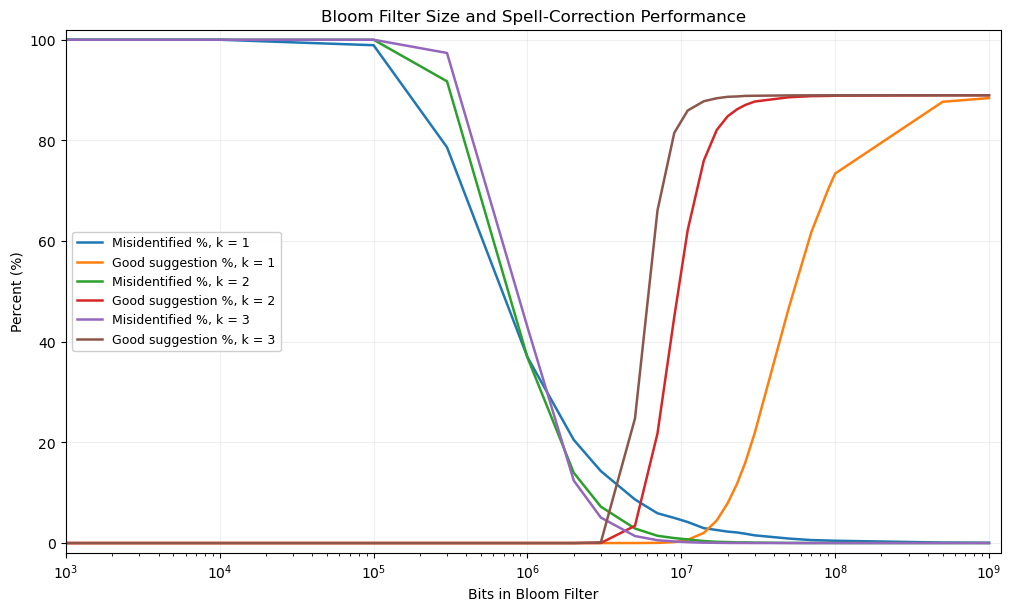

In [24]:
import csv
import matplotlib.pyplot as plt

# Read the results from the parallel experiment.
with open("part2-results-parallel.csv", encoding="utf-8") as f:
    plot_results = [
        {
            "size": int(row["filter_size_bits"]),
            "k": int(row["hash_count"]),
            "misidentified": float(row["misidentified_percent"]),
            "good_suggestion": float(row["good_suggestion_percent"]),
        }
        for row in csv.DictReader(f)
    ]

# Check how many completed configurations are available.
for k in (1, 2, 3):
    count = sum(row["k"] == k for row in plot_results)
    print(f"k = {k}: {count} filter sizes")

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

# Use six colors, matching the order of the exercise's reference plot.
colors = {
    1: ("tab:blue", "tab:orange"),
    2: ("tab:green", "tab:red"),
    3: ("tab:purple", "tab:brown"),
}

# Set to True to display the measured points.
show_points = False

for k in (1, 2, 3):
    selected = sorted(
        [row for row in plot_results if row["k"] == k],
        key=lambda row: row["size"],
    )

    sizes = [row["size"] for row in selected]
    misidentified = [row["misidentified"] for row in selected]
    good_suggestion = [row["good_suggestion"] for row in selected]

    ax.plot(
        sizes,
        misidentified,
        color=colors[k][0],
        linewidth=1.8,
        marker="o" if show_points else None,
        markersize=3,
        label=f"Misidentified %, k = {k}",
    )

    ax.plot(
        sizes,
        good_suggestion,
        color=colors[k][1],
        linewidth=1.8,
        marker="o" if show_points else None,
        markersize=3,
        label=f"Good suggestion %, k = {k}",
    )

ax.set_xscale("log")
ax.set_xlim(
    min(row["size"] for row in plot_results),
    max(row["size"] for row in plot_results) * 1.2,
)
ax.set_ylim(-2, 102)
ax.set_yticks(range(0, 101, 20))

ax.set_xlabel("Bits in Bloom Filter")
ax.set_ylabel("Percent (%)")
ax.set_title("Bloom Filter Size and Spell-Correction Performance")

ax.grid(True, which="major", alpha=0.2)
ax.legend(loc="center left", fontsize=9, framealpha=0.95)

fig.savefig(
    "part2-filter-size-combined.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()